In [1]:
%pip install -U ucimlrepo pandas numpy scikit-learn matplotlib gradio flask

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
raisin_data = fetch_ucirepo(id=850)

X_raisin = raisin_data.data.features.copy()
y_raisin = raisin_data.data.targets.copy()

print("Raisin dataset loaded successfully!")
print("Feature shape:", X_raisin.shape)
print("Target shape:", y_raisin.shape)

display(X_raisin.head())
display(y_raisin.head())

Raisin dataset loaded successfully!
Feature shape: (900, 7)
Target shape: (900, 1)


,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter
0,87524,442.246011,253.291155,0.819738,90546,0.758651,1184.040
1,75166,406.690687,243.032436,0.801805,78789,0.684130,1121.786
2,90856,442.267048,266.328318,0.798354,93717,0.637613,1208.575
3,45928,286.540559,208.760042,0.684989,47336,0.699599,844.162
4,79408,352.190770,290.827533,0.564011,81463,0.792772,1073.251


,Class
0,Kecimen
1,Kecimen
2,Kecimen
3,Kecimen
4,Kecimen


In [4]:
wine_data = fetch_ucirepo(id=186)

X_wine = wine_data.data.features.copy()
y_wine_original = wine_data.data.targets.copy()

print("Wine Quality dataset loaded successfully!")
print("Feature shape:", X_wine.shape)
print("Target shape:", y_wine_original.shape)

display(X_wine.head())
display(y_wine_original.head())

Wine Quality dataset loaded successfully!
Feature shape: (6497, 11)
Target shape: (6497, 1)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4


,quality
0,5
1,5
2,5
3,6
4,5


In [5]:
print("Raisin feature columns:")
print(X_raisin.columns.tolist())

print("\nRaisin target columns:")
print(y_raisin.columns.tolist())

print("\nRaisin class counts:")
print(y_raisin.iloc[:, 0].value_counts())

print("\nWine feature columns:")
print(X_wine.columns.tolist())

print("\nWine target columns:")
print(y_wine_original.columns.tolist())

Raisin feature columns:
['Area', 'MajorAxisLength', 'MinorAxisLength', 'Eccentricity', 'ConvexArea', 'Extent', 'Perimeter']

Raisin target columns:
['Class']

Raisin class counts:
Class
Kecimen    450
Besni      450
Name: count, dtype: int64

Wine feature columns:
['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar', 'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density', 'pH', 'sulphates', 'alcohol']

Wine target columns:
['quality']


In [6]:
raisin_df = pd.concat(
    [X_raisin, y_raisin],
    axis=1
).dropna().reset_index(drop=True)

raisin_target_column = y_raisin.columns[0]
raisin_feature_columns = X_raisin.columns.tolist()

X_raisin = raisin_df[raisin_feature_columns].copy()

raisin_label_map = {
    "Besni": 0,
    "Kecimen": 1
}

y_raisin = (
    raisin_df[raisin_target_column]
    .astype(str)
    .map(raisin_label_map)
)

if y_raisin.isna().any():
    raise ValueError("Unexpected Raisin class label. Check Cell 5.")

y_raisin = y_raisin.astype(int)

print("Raisin dataset prepared!")
print("Feature columns:", raisin_feature_columns)
print("Class counts:")
print(y_raisin.map({0: "Besni", 1: "Kecimen"}).value_counts())

Raisin dataset prepared!
Feature columns: ['Area', 'MajorAxisLength', 'MinorAxisLength', 'Eccentricity', 'ConvexArea', 'Extent', 'Perimeter']
Class counts:
Class
Kecimen    450
Besni      450
Name: count, dtype: int64


In [7]:
wine_target_column = y_wine_original.columns[0]

wine_df = pd.concat(
    [X_wine, y_wine_original],
    axis=1
).dropna().reset_index(drop=True)

wine_feature_columns = X_wine.columns.tolist()

X_wine = wine_df[wine_feature_columns].copy()

# 0 = Lower quality (score below 6)
# 1 = Higher quality (score 6 or above)

y_wine = (
    wine_df[wine_target_column]
    .astype(float)
    .ge(6)
    .astype(int)
)

print("Wine dataset prepared!")
print("Feature columns:", wine_feature_columns)

print("\nClass counts:")
print(
    y_wine.map({
        0: "Lower quality",
        1: "Higher quality"
    }).value_counts()
)

Wine dataset prepared!
Feature columns: ['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar', 'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density', 'pH', 'sulphates', 'alcohol']

Class counts:
quality
Higher quality    4113
Lower quality     2384
Name: count, dtype: int64


In [8]:
X_raisin_train, X_raisin_test, y_raisin_train, y_raisin_test = (
    train_test_split(
        X_raisin,
        y_raisin,
        test_size=0.20,
        random_state=42,
        stratify=y_raisin
    )
)

X_wine_train, X_wine_test, y_wine_train, y_wine_test = (
    train_test_split(
        X_wine,
        y_wine,
        test_size=0.20,
        random_state=42,
        stratify=y_wine
    )
)

print("RAISIN")
print("Training records:", len(X_raisin_train))
print("Testing records:", len(X_raisin_test))

print("\nWINE QUALITY")
print("Training records:", len(X_wine_train))
print("Testing records:", len(X_wine_test))

RAISIN
Training records: 720
Testing records: 180

WINE QUALITY
Training records: 5197
Testing records: 1300


In [9]:
raisin_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000))
])

raisin_model.fit(
    X_raisin_train,
    y_raisin_train
)

print("Raisin Logistic Regression model trained successfully!")

Raisin Logistic Regression model trained successfully!


In [10]:
wine_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000))
])

wine_model.fit(
    X_wine_train,
    y_wine_train
)

print("Wine Quality Logistic Regression model trained successfully!")

Wine Quality Logistic Regression model trained successfully!


In [11]:
def evaluate_classifier(model, X_test, y_test, class_names, model_name):
    predictions = model.predict(X_test)

    print(f"\n{model_name}")
    print("=" * 45)
    print(f"Accuracy : {accuracy_score(y_test, predictions):.4f}")
    print(
        "Precision:",
        f"{precision_score(y_test, predictions, zero_division=0):.4f}"
    )
    print(
        "Recall   :",
        f"{recall_score(y_test, predictions, zero_division=0):.4f}"
    )
    print(
        "F1 Score :",
        f"{f1_score(y_test, predictions, zero_division=0):.4f}"
    )

    print("\nClassification Report:")
    print(
        classification_report(
            y_test,
            predictions,
            labels=[0, 1],
            target_names=class_names,
            zero_division=0
        )
    )

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=[0, 1],
        display_labels=class_names
    )

    plt.title(f"{model_name} - Confusion Matrix")
    plt.tight_layout()
    plt.show()

    return predictions


Raisin Classification
Accuracy : 0.8889
Precision: 0.8500
Recall   : 0.9444
F1 Score : 0.8947

Classification Report:
              precision    recall  f1-score   support

       Besni       0.94      0.83      0.88        90
     Kecimen       0.85      0.94      0.89        90

    accuracy                           0.89       180
   macro avg       0.89      0.89      0.89       180
weighted avg       0.89      0.89      0.89       180



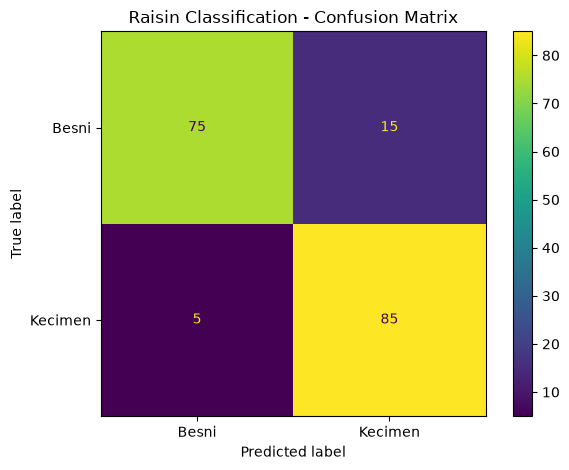

In [12]:
raisin_predictions = evaluate_classifier(
    raisin_model,
    X_raisin_test,
    y_raisin_test,
    ["Besni", "Kecimen"],
    "Raisin Classification"
)


Wine Quality Classification
Accuracy : 0.7338
Precision: 0.7624
Recall   : 0.8420
F1 Score : 0.8002

Classification Report:
                precision    recall  f1-score   support

 Lower quality       0.67      0.55      0.60       477
Higher quality       0.76      0.84      0.80       823

      accuracy                           0.73      1300
     macro avg       0.71      0.69      0.70      1300
  weighted avg       0.73      0.73      0.73      1300



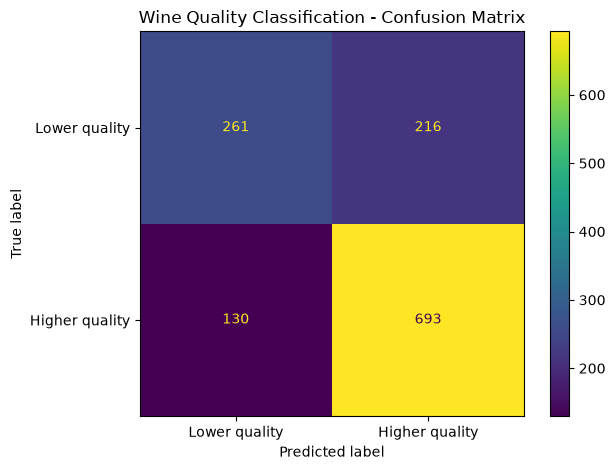

In [13]:
wine_predictions = evaluate_classifier(
    wine_model,
    X_wine_test,
    y_wine_test,
    ["Lower quality", "Higher quality"],
    "Wine Quality Classification"
)

In [14]:
import gradio as gr

raisin_class_names = {
    0: "Besni",
    1: "Kecimen"
}

def predict_raisin_gradio(*values):
    input_data = pd.DataFrame(
        [values],
        columns=raisin_feature_columns
    )

    prediction = int(raisin_model.predict(input_data)[0])
    probabilities = raisin_model.predict_proba(input_data)[0]

    confidence = float(probabilities[prediction]) * 100

    return (
        f"Predicted Raisin Variety: {raisin_class_names[prediction]}\n"
        f"Model probability for predicted class: {confidence:.2f}%"
    )

In [15]:
raisin_gradio_inputs = [
    gr.Number(
        label=column,
        value=float(X_raisin_train[column].median())
    )
    for column in raisin_feature_columns
]

raisin_demo = gr.Interface(
    fn=predict_raisin_gradio,
    inputs=raisin_gradio_inputs,
    outputs=gr.Textbox(label="Classification Result"),
    title="Raisin Variety Classifier",
    description=(
        "Enter the seven measured features of a raisin "
        "to predict whether it is Besni or Kecimen."
    )
)

raisin_demo.launch()

* Running on local URL:  http://127.0.0.1:7864
* To create a public link, set `share=True` in `launch()`.


Created dataset file at: .gradio\flagged\dataset5.csv


In [16]:
wine_class_names = {
    0: "Lower quality",
    1: "Higher quality"
}

def predict_wine_gradio(*values):
    input_data = pd.DataFrame(
        [values],
        columns=wine_feature_columns
    )

    prediction = int(wine_model.predict(input_data)[0])
    probabilities = wine_model.predict_proba(input_data)[0]

    confidence = float(probabilities[prediction]) * 100

    return (
        f"Predicted Wine Category: {wine_class_names[prediction]}\n"
        f"Model probability for predicted class: {confidence:.2f}%"
    )

In [17]:
wine_gradio_inputs = [
    gr.Number(
        label=column.replace("_", " ").title(),
        value=float(X_wine_train[column].median())
    )
    for column in wine_feature_columns
]

wine_demo = gr.Interface(
    fn=predict_wine_gradio,
    inputs=wine_gradio_inputs,
    outputs=gr.Textbox(label="Classification Result"),
    title="Wine Quality Classifier",
    description=(
        "Enter the 11 physicochemical measurements "
        "to predict the lower-quality or higher-quality category."
    )
)

wine_demo.launch()

* Running on local URL:  http://127.0.0.1:7865
* To create a public link, set `share=True` in `launch()`.


Created dataset file at: .gradio\flagged\dataset6.csv


In [18]:
from flask import Flask, request, render_template_string
from threading import Thread
import time

app = Flask(__name__)

print("Flask app created successfully!")

Flask app created successfully!


In [19]:
HOME_TEMPLATE = """
<!DOCTYPE html>
<html>
<head>
    <title>Classification Project</title>
</head>
<body style="font-family:Arial; margin:40px;">
    <h1>Logistic Regression Classification System</h1>
    <p>Select a model:</p>
    <ul>
        <li><a href="/raisin">Raisin Variety Classifier</a></li>
        <li><a href="/wine">Wine Quality Classifier</a></li>
    </ul>
</body>
</html>
"""

FORM_TEMPLATE = """
<!DOCTYPE html>
<html>
<head>
    <title>{{ title }}</title>
    <style>
        body {
            font-family: Arial, sans-serif;
            max-width: 800px;
            margin: 30px auto;
            padding: 20px;
            background: #f4f6f8;
        }
        .container {
            background: white;
            padding: 25px;
            border-radius: 10px;
        }
        label {
            display: block;
            margin-top: 12px;
            font-weight: bold;
        }
        input {
            width: 95%;
            padding: 8px;
            margin-top: 5px;
        }
        button {
            margin-top: 20px;
            padding: 12px 18px;
            cursor: pointer;
        }
        .result {
            margin-top: 20px;
            padding: 12px;
            background: #e8f5e9;
            border-radius: 5px;
        }
    </style>
</head>
<body>
<div class="container">
    <h1>{{ title }}</h1>
    <p>{{ description }}</p>

    <form method="POST">
        {% for field in fields %}
            <label>{{ field.label }}</label>
            <input
                type="number"
                step="any"
                name="{{ field.name }}"
                value="{{ field.value }}"
                required
            >
        {% endfor %}
        <button type="submit">Classify</button>
    </form>

    {% if result %}
        <div class="result">
            <strong>{{ result }}</strong>
        </div>
    {% endif %}

    <p><a href="/">Back to Home</a></p>
</div>
</body>
</html>
"""

print("HTML templates created successfully!")

HTML templates created successfully!


In [20]:
@app.route("/")
def home():
    return render_template_string(HOME_TEMPLATE)

In [21]:
def render_classifier_page(
    model,
    feature_columns,
    class_names,
    title,
    description,
    route_key
):
    defaults = {
        "raisin": X_raisin_train.median(),
        "wine": X_wine_train.median()
    }

    fields = []

    for column in feature_columns:
        default_value = float(defaults[route_key][column])

        fields.append({
            "name": column,
            "label": column.replace("_", " ").title(),
            "value": request.form.get(column, str(default_value))
        })

    result = None

    if request.method == "POST":
        try:
            values = [
                float(request.form[column])
                for column in feature_columns
            ]

            if not all(np.isfinite(value) for value in values):
                raise ValueError("Please enter finite numerical values.")

            input_data = pd.DataFrame(
                [values],
                columns=feature_columns
            )

            prediction = int(model.predict(input_data)[0])
            probabilities = model.predict_proba(input_data)[0]
            confidence = float(probabilities[prediction]) * 100

            result = (
                f"Predicted Category: {class_names[prediction]} "
                f"(model probability: {confidence:.2f}%)"
            )

        except ValueError as error:
            result = f"Input error: {error}"

    return render_template_string(
        FORM_TEMPLATE,
        title=title,
        description=description,
        fields=fields,
        result=result
    )